# The Riemann spectrum and the staircase of primes

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), chapter "The spectrum and the staircase of primes" and Part III, "The Riemann Spectrum of the Prime Numbers".*

> To manage to repackage the "same" data in various ways—where each way brings out some features that would be kept in the shadows if the data were packaged in some different way—is a high art, in mathematics.

The book's answer to "does the staircase of primes have a spectrum?" is yes. The spectrum is the list of numbers
$$\theta_1 = 14.1347\ldots,\quad \theta_2 = 21.0220\ldots,\quad \theta_3 = 25.0108\ldots,\quad \ldots$$
where $\tfrac12 + i\theta_k$ are the zeros of $\zeta(s)$ (the Riemann Hypothesis says *all* the nontrivial zeros have this form). In this notebook you will see the two directions of this correspondence, and then rebuild the staircase of primes from its spectrum:

1. Chebyshev's staircase $\psi(x)$, a "tinkered" staircase of primes that hugs the line $y = x$;
2. from the spectrum to the primes: a sum of waves, one per zero, that spikes at the prime powers;
3. from the primes to the spectrum: a sum of waves, one per prime power, that spikes at the zeros;
4. the staircase rebuilt from the first $k$ zeros: Riemann's explicit formula.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
GAMMA = np.array([float(line) for line in open('zeta_zeros_1000.txt') if not line.startswith('#')])
print(len(GAMMA), 'zeros of zeta (from the file beside this notebook); theta_1, theta_2, theta_3 =', GAMMA[:3])

1000 zeros of zeta (from the file beside this notebook); theta_1, theta_2, theta_3 = [14.13472514 21.02203964 25.01085758]


## 1. The tinkered staircase: $\psi(x)$

The staircase $\pi(x)$ steps up by $1$ at each prime. Chebyshev's function
$$\psi(x) = \sum_{p^n \le x} \log p$$
steps up by $\log p$ at each prime power $p^n$. That small change makes it hug the diagonal: the Prime Number Theorem is equivalent to $\psi(x) \sim x$, and the Riemann Hypothesis to $\psi(x) = x + O(\sqrt{x}\,\log^2 x)$.

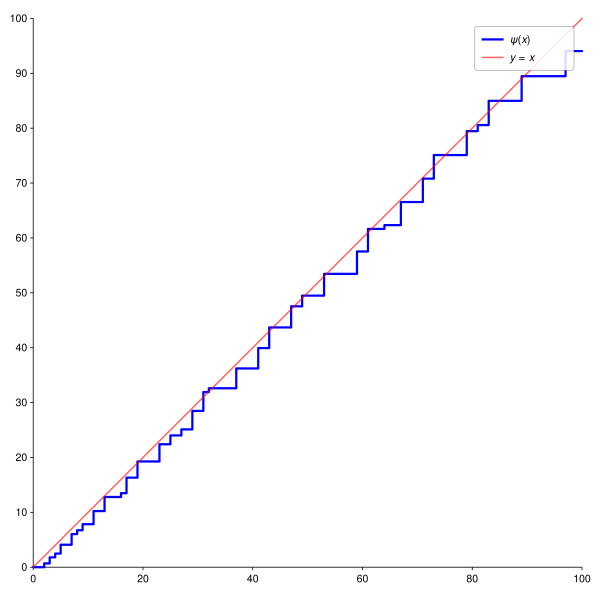

In [2]:
def psi_steps(X):
    "The points (x, psi(x)) where Chebyshev's psi steps up, for x <= X, as a step function."
    pts = [(0, 0)]
    y = 0.0
    for q in prime_powers(2, X + 1):
        pts.append((q, y))
        y += float(log(factor(q)[0][0]))
        pts.append((q, y))
    pts.append((X, y))
    return pts

@interact
def psi_staircase(X=selector([10, 40, 100, 1000, 10^4], default=100, label='x up to')):
    g = line(psi_steps(X), color='blue', thickness=1.5, legend_label=r'$\psi(x)$')
    g += plot(lambda t: t, (0, X), color='red', alpha=0.6, legend_label=r'$y = x$')
    show(g, aspect_ratio=1 if X <= 100 else 'automatic', figsize=[6, 6] if X <= 100 else [8, 4], gridlines=X <= 40)

## 2. From the spectrum to the primes

Take the first $m$ numbers of the spectrum and add up one wave for each:
$$\phi_m(s) = -\sum_{k=1}^{m} \cos(\theta_k \log s).$$
Nothing in this formula mentions primes. Yet as $m$ grows the sum develops sharp spikes, and they are exactly at the **prime powers** $2, 3, 4, 5, 7, 8, 9, 11, 13, 16, \ldots$ (the red dots, larger for larger primes): the spectrum knows where the primes are.

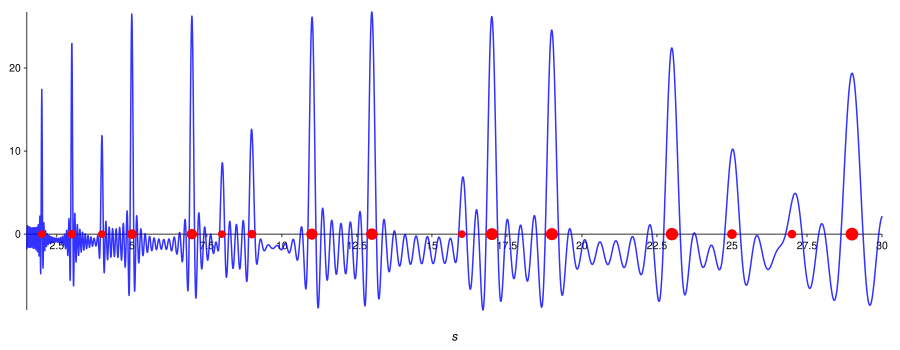

In [3]:
@interact
def spectrum_to_primes(m=selector([5, 20, 100, 300, 1000], default=100, label='zeros used'),
                       upto=selector([30, 100, 200], default=30, label='s up to')):
    s = np.linspace(1.5, upto, 4000)
    phi = -np.cos(np.outer(np.log(s), GAMMA[:m])).sum(axis=1)
    g = list_plot(list(zip(s, phi)), plotjoined=True, color='blue', alpha=0.8)
    top = max(phi.max(), 1)
    for q in prime_powers(2, upto + 1):
        p = factor(q)[0][0]
        g += point((q, 0), size=12 * float(log(p)) + 10, color='red', zorder=5)
    show(g, figsize=[9, 3.5], axes_labels=['$s$', ''])

## 3. From the primes to the spectrum

The correspondence also runs the other way. Add up one wave for each prime power $q = p^n \le C$:
$$T_C(\theta) = \sum_{p^n \le C} 2\,p^{-n/2}\,\log p\,\cos(n \log p \cdot \theta).$$
Now the formula mentions only primes, yet as $C$ grows the sum develops sharp dips at the numbers of the **Riemann spectrum** $\theta_1, \theta_2, \ldots$. Below we plot $-T_C(\theta)$, so they show as spikes, against the red marks at the $\theta_k$: the primes know where the zeros are.

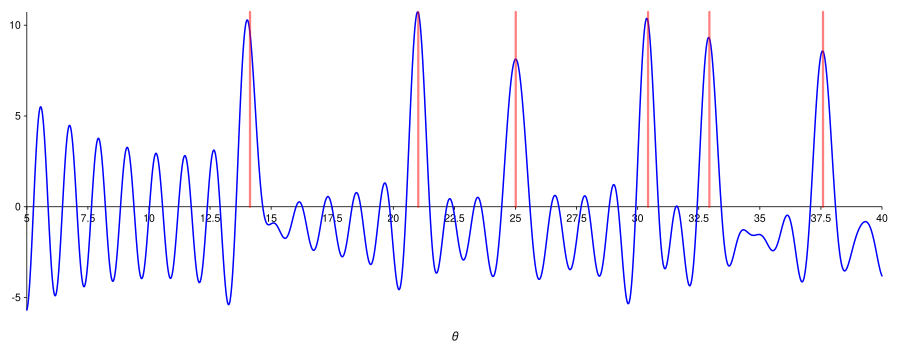

In [4]:
@interact
def primes_to_spectrum(C=selector([10, 50, 200, 1000, 5000], default=200, label='prime powers up to C'),
                       upto=selector([40, 100], default=40, label='theta up to')):
    theta = np.linspace(5, upto, 3000)
    T = np.zeros_like(theta)
    for q in prime_powers(2, C + 1):
        p, n = factor(q)[0]
        T += 2 * float(p)**(-n / 2) * float(log(p)) * np.cos(n * float(log(p)) * theta)
    g = list_plot(list(zip(theta, -T)), plotjoined=True, color='blue')
    y = (-T).max()
    for t0 in GAMMA[GAMMA <= upto]:
        g += line([(t0, 0), (t0, y)], color='red', alpha=0.5, thickness=1.5)
    show(g, figsize=[9, 3.5], axes_labels=[r'$\theta$', ''])

## 4. Rebuilding the staircase from its spectrum

Riemann's explicit formula (in von Mangoldt's form) makes the correspondence exact:
$$\psi(x) \;=\; x \;-\; \sum_{\rho} \frac{x^{\rho}}{\rho} \;-\; \log 2\pi \;-\; \tfrac12 \log\!\left(1 - x^{-2}\right),$$
where $\rho$ runs over the nontrivial zeros, in pairs $\rho = \tfrac12 \pm i\theta_k$ (at the jumps, $\psi$ takes the average of its two values). Each pair contributes a wave $-2\,\mathrm{Re}\,(x^{\rho}/\rho)$, of size about $\sqrt{x}/\theta_k$ and frequency $\theta_k$ in $\log x$. Using only the first $k$ zeros gives a smooth curve; drag $k$ up and watch it become the staircase.

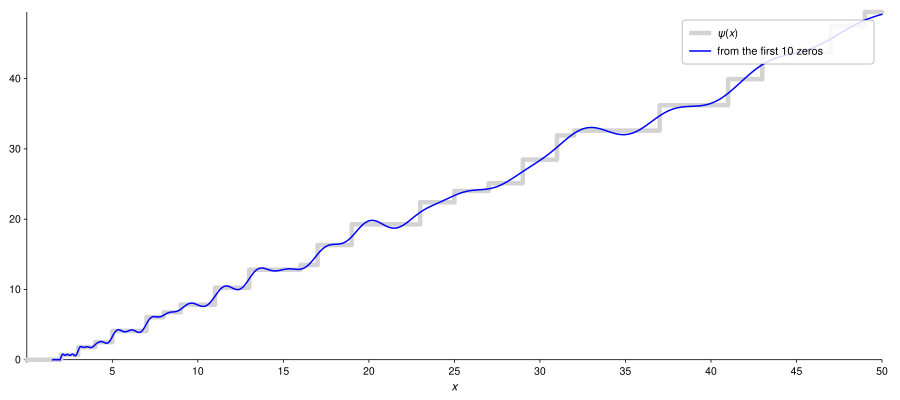

In [5]:
def psi_from_zeros(x, k):
    "Riemann's explicit formula for psi(x), using the first k zeros (in conjugate pairs)."
    rho = 0.5 + 1j * GAMMA[:k]
    waves = np.exp(np.outer(np.log(x), rho)) / rho
    return x - 2 * waves.real.sum(axis=1) - np.log(2 * np.pi) - 0.5 * np.log(1 - x**-2.0)

@interact
def rebuild(k=selector([1, 3, 10, 30, 100, 300, 1000], default=10, label='zeros used'),
            X=selector([20, 50, 100], default=50, label='x up to')):
    x = np.linspace(1.5, X, 3000)
    g = line(psi_steps(X), color='lightgray', thickness=3, legend_label=r'$\psi(x)$')
    g += list_plot(list(zip(x, psi_from_zeros(x, k))), plotjoined=True, color='blue',
                   legend_label='from the first %d zeros' % k)
    show(g, figsize=[9, 4], axes_labels=['$x$', ''])

This is the sense in which the Riemann spectrum is the spectrum of the primes: the numbers $\theta_k$ are the frequencies, and $\sqrt{x}/|\rho|$ the amplitudes, of the waves that add up to the staircase. The Riemann Hypothesis, that every $\rho$ has real part $\tfrac12$, says all the waves grow at the same rate $\sqrt{x}$, which is why the error in the Prime Number Theorem is square-root size (see *How good is $\operatorname{Li}(x)$?*). A zero off the line would be a wave growing faster than all the others; the newly proved quasi-Riemann Hypothesis rules out zeros with real part above $\tfrac{11}{12}$.

## Things to try

1. In section 2, how many zeros do you need before every prime power up to $30$ shows a clear spike? Do prime squares like $9$ and $25$ spike as strongly as primes? Why (look at the weights in section 3)?
2. In section 4, measure the error $|\psi(x) - \text{formula}|$ at $x = 50.5$ (between prime powers) for $k = 10, 100, 1000$. How fast does it shrink?
3. Change `psi_from_zeros` so that the first zero has real part $0.8$ instead of $\tfrac12$. What happens to the curve for large $x$?

---
*Adapted and greatly expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. The zeros in `zeta_zeros_1000.txt` were computed with mpmath. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*